# Survival: from person-periods to risk sets

Discrete-time survival models are fitted to a *person-period* table: one row per subject per period at risk,
with a 0/1 event flag. When covariates are categorical, every row in a cell $c = (\text{period}, \text{covariates})$
has the same hazard $h_c$, so the Bernoulli rows reduce to

$$\prod_{i \in c} h_c^{y_i}(1-h_c)^{1-y_i} = h_c^{d_c}(1-h_c)^{r_c-d_c}, \qquad T = (d_c, r_c),$$

the number of events and the number at risk in each cell. This is the life table. The continuous-time
analogue is the piecewise-exponential model. A subject contributes exposure $e_{ij}$ and an event flag $y_{ij}$
to interval $j$, and the likelihood $\prod \lambda_c^{y_{ij}} e^{-\lambda_c e_{ij}}$ depends only on $(d_c, E_c)$,
events and total exposure. That is why a Poisson regression with a log-exposure offset is a survival model.

The [discrete-time survival notebook](https://nathanielf.github.io/oss/bambi/survival_discrete_time_notebook.html)
applies this to real data with Bambi. Here we show what the fitted model is used for (survival curves and a
treatment contrast), then compare raw-row and cell-summary fits.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(303)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Simulated data

40,000 subjects, a treatment flag and three groups (A, B, C; A is the reference), followed for 8 periods.
The hazard is constant within each unit interval, so the same draws serve the discrete-time view (did the
event happen in period $j$?) and the continuous-time view (when exactly?).

Subjects are censored at period boundaries. If they could be censored part-way through a period, the
discrete model would count them as surviving that period, which biases its hazard down. The usual
correction is the actuarial one: count such subjects as at risk for half the period, $r - c/2$.

In [2]:
n_sub, J = 40_000, 8
GROUPS = ["A", "B", "C"]
treat = rng.integers(0, 2, n_sub)
group = rng.integers(0, 3, n_sub)
base_log_haz = np.log(np.array([0.05, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18]))
beta_treat, beta_group = -0.4, np.array([0.0, 0.25, 0.5])

t_event = np.full(n_sub, np.inf)
alive = np.ones(n_sub, bool)
for j in range(J):
    lam = np.exp(base_log_haz[j] + beta_treat * treat + beta_group[group])
    w = rng.exponential(1 / lam)
    hit = alive & (w < 1)
    t_event[hit] = j + w[hit]
    alive &= ~hit
t_cens = np.minimum(rng.integers(2, 13, n_sub), J).astype(float)     # censoring at period boundaries
T = np.minimum(t_event, t_cens)
event = (t_event <= t_cens).astype(int)

period = np.arange(J)
exposure = np.clip(T[:, None] - period[None, :], 0, 1)
at_risk = exposure > 0
pp = pd.DataFrame({
    "id": np.repeat(np.arange(n_sub), J)[at_risk.ravel()],
    "period": np.tile(period, n_sub)[at_risk.ravel()],
    "exposure": exposure.ravel()[at_risk.ravel()],
})
pp["treat"], pp["group"] = treat[pp.id], group[pp.id]
pp["y"] = ((np.floor(T[pp.id]) == pp.period) & (event[pp.id] == 1)).astype(int)
print(f"{n_sub:,} subjects -> {len(pp):,} person-period rows, {pp.y.sum():,} events")

40,000 subjects -> 194,658 person-period rows, 18,160 events


The compression step is one `groupby`. The table holds both sufficient statistics: the number at risk $r$
for the discrete model and the total exposure $E$ for the continuous one.

In [3]:
cells = (pp.groupby(["period", "treat", "group"])
           .agg(d=("y", "sum"), r=("y", "size"), E=("exposure", "sum"))
           .reset_index())
print(f"{len(pp):,} rows -> {len(cells)} cells")
cells.head()

194,658 rows -> 48 cells


,period,treat,group,d,r,E
0,0,0,0,308,6707,6550.569048
1,0,0,1,398,6662,6455.806078
2,0,0,2,538,6678,6410.102973
3,0,1,0,237,6741,6617.321175
4,0,1,1,293,6634,6490.146197


## Four fits of one linear predictor

The linear predictor is the same throughout: a log-hazard per period plus treatment and group effects. The
discrete model uses the complementary log-log link $h = 1 - \exp(-e^{\eta})$, which makes it a grouped form of
a proportional-hazards model. Only the likelihood, and the number of rows it covers, changes.

In [4]:
coords = {"period": period, "group_eff": GROUPS[1:]}


def linpred(df):
    a = pm.Normal("alpha", -2, 1.5, dims="period")
    b_t = pm.Normal("beta_treat", 0, 1)
    b_g = pm.Normal("beta_group", 0, 1, dims="group_eff")
    g = pm.math.concatenate([[0.0], b_g])
    return a[df.period.values] + b_t * df.treat.values + g[df.group.values]


def cloglog_inv(eta):
    return 1 - pm.math.exp(-pm.math.exp(eta))


with pm.Model(coords=coords) as disc_full:
    pm.Bernoulli("y", p=cloglog_inv(linpred(pp)), observed=pp.y.values)

with pm.Model(coords=coords) as disc_suff:
    pm.Binomial("d", n=cells.r.values, p=cloglog_inv(linpred(cells)), observed=cells.d.values)

with pm.Model(coords=coords) as pwe_full:
    pm.Poisson("y", mu=pp.exposure.values * pm.math.exp(linpred(pp)), observed=pp.y.values)

with pm.Model(coords=coords) as pwe_suff:
    pm.Poisson("d", mu=cells.E.values * pm.math.exp(linpred(cells)), observed=cells.d.values)

fits = {}
for key, name, model, n_rows, case, kind in [
        ("disc_raw", "cloglog, person-period rows", disc_full, len(pp), "Discrete-time survival", "raw"),
        ("disc_cells", "cloglog Binomial, (d, r) per cell", disc_suff, len(cells), "Discrete-time survival", "compressed"),
        ("pwe_raw", "piecewise-exp, person-period rows", pwe_full, len(pp), "Piecewise exponential", "raw"),
        ("pwe_cells", "piecewise-exp Poisson, (d, E) per cell", pwe_suff, len(cells), "Piecewise exponential", "compressed")]:
    fits[key] = timed_fit(model, name, n_rows, case, kind)

NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]
NUTS[nutpie]: [alpha, beta_treat, beta_group]


## What the model is for: survival curves and a treatment contrast

From the piecewise-exponential posterior, survival at time $t$ in interval $j$ is
$S(t) = \exp\{-\sum_{m<j}\lambda_m - \lambda_j (t-j)\}$. We draw it for every treatment × group stratum and
overlay the Kaplan–Meier estimate from the raw subjects. Agreement between the two is a visual check of the
model.

A single-number summary of a survival curve is the **restricted mean survival time** (RMST): the expected
event-free time up to a horizon, here 8 periods, which is the area under $S(t)$. The treatment contrast
below is the difference in RMST and in $S(8)$, averaged over the three groups.

In [5]:
def kaplan_meier(t, d):
    order = np.argsort(t)
    t, d = t[order], d[order]
    times = np.unique(t[d == 1])
    n_at_risk = np.array([(t >= u).sum() for u in times])
    deaths = np.array([((t == u) & (d == 1)).sum() for u in times])
    return np.concatenate([[0], times]), np.concatenate([[1], np.cumprod(1 - deaths / n_at_risk)])


post = fits["pwe_cells"].posterior
a = post["alpha"].values.reshape(-1, J)
bt = post["beta_treat"].values.reshape(-1, 1)
bg = np.column_stack([np.zeros(a.shape[0]), post["beta_group"].values.reshape(a.shape[0], -1)])


def log_haz(tr, g):
    return a + bt * tr + bg[:, [g]]                                       # (draw, J)


def surv_curve(lh, grid):
    lam = np.exp(lh)
    cum = np.concatenate([np.zeros((lam.shape[0], 1)), np.cumsum(lam, 1)], 1)    # cumulative hazard at integers
    j = np.minimum(np.floor(grid).astype(int), J - 1)
    return np.exp(-(cum[:, j] + lam[:, j] * (grid - j)))


def rmst(lh):
    lam = np.exp(lh)
    S_start = np.exp(-np.concatenate([np.zeros((lam.shape[0], 1)), np.cumsum(lam, 1)[:, :-1]], 1))
    return (S_start * (1 - np.exp(-lam)) / lam).sum(1)


grid = np.linspace(0, J, 161)
d_rmst = np.mean([rmst(log_haz(1, g)) - rmst(log_haz(0, g)) for g in range(3)], 0)
d_S8 = np.mean([np.exp(-np.exp(log_haz(1, g)).sum(1)) - np.exp(-np.exp(log_haz(0, g)).sum(1)) for g in range(3)], 0)

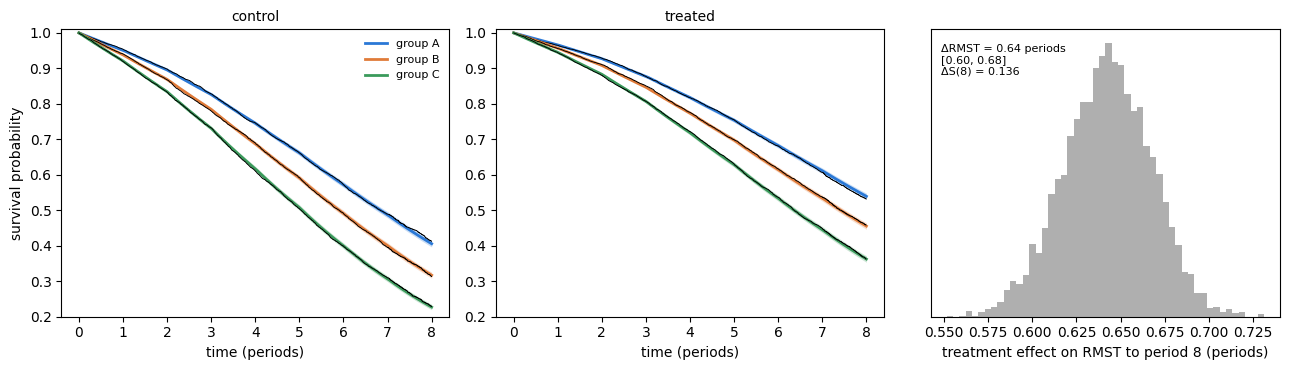

In [6]:
#| label: fig-surv-use
#| fig-cap: "Left and centre: posterior survival curves (line and 89% band) from the piecewise-exponential cell-summary fit, by group, for control and treated subjects, with Kaplan–Meier steps from the raw subjects (thin). Right: posterior of the treatment effect on restricted mean survival time to period 8 and on survival at period 8, averaged over groups."
cols = ["#2a78d6", "#e07b39", "#3a9a5b"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, tr in zip(axes[:2], [0, 1]):
    for g, col in enumerate(cols):
        S = surv_curve(log_haz(tr, g), grid)
        lo, hi = np.quantile(S, [0.055, 0.945], 0)
        ax.fill_between(grid, lo, hi, color=col, alpha=0.25, lw=0)
        ax.plot(grid, S.mean(0), color=col, lw=2, label=f"group {GROUPS[g]}")
        m = (treat == tr) & (group == g)
        kt, ks = kaplan_meier(T[m], event[m])
        ax.step(kt, ks, where="post", color="k", lw=0.6)
    ax.set_title("treated" if tr else "control", fontsize=10)
    ax.set_xlabel("time (periods)")
    ax.set_ylim(0.2, 1.01)
axes[0].set_ylabel("survival probability")
axes[0].legend(frameon=False, fontsize=8)
ax = axes[2]
ax.hist(d_rmst, bins=50, density=True, color="#7a7a7a", alpha=0.6)
ax.set_xlabel("treatment effect on RMST to period 8 (periods)")
ax.set_yticks([])
ax.text(0.03, 0.95, f"ΔRMST = {d_rmst.mean():.2f} periods\n[{np.quantile(d_rmst, .055):.2f}, {np.quantile(d_rmst, .945):.2f}]\n"
        f"ΔS(8) = {d_S8.mean():.3f}", transform=ax.transAxes, va="top", fontsize=8)
plt.tight_layout()
plt.show()

## Raw rows vs cell summaries

The cloglog model on period indicators and the piecewise-exponential model on exact exposures are
different models of the same data, so they need not agree with each other. Each compressed fit agrees with
its own raw-row fit.

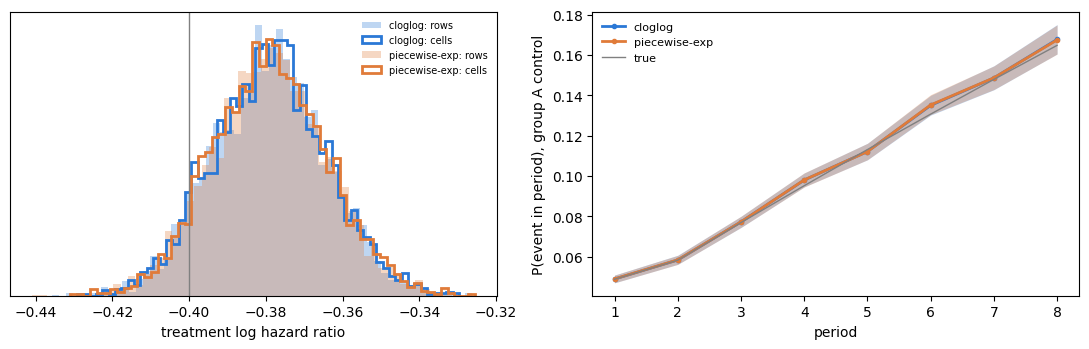

In [7]:
#| label: fig-surv-equiv
#| fig-cap: "Colour marks the model (blue: discrete cloglog; orange: piecewise-exponential); filled is the raw-row fit, line is the cell-summary fit. Left: treatment log hazard ratio, true value in grey. Right: baseline hazard per period for control subjects in reference group A, as the probability of an event in the period, with 89% bands for the raw-row fits and the true values in grey."
pairs = {"cloglog": ("disc_raw", "disc_cells", "#2a78d6"), "piecewise-exp": ("pwe_raw", "pwe_cells", "#e07b39")}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for name, (raw, cel, col) in pairs.items():
    ax.hist(fits[raw].posterior["beta_treat"].values.ravel(), bins=60, density=True, alpha=0.3, color=col, label=f"{name}: rows")
    ax.hist(fits[cel].posterior["beta_treat"].values.ravel(), bins=60, density=True, histtype="step", lw=2, color=col, label=f"{name}: cells")
ax.axvline(beta_treat, color="grey", lw=1)
ax.set_yticks([])
ax.set_xlabel("treatment log hazard ratio")
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
x = period + 1
for name, (raw, cel, col) in pairs.items():
    h_raw = 1 - np.exp(-np.exp(fits[raw].posterior["alpha"].values.reshape(-1, J)))
    h_cel = 1 - np.exp(-np.exp(fits[cel].posterior["alpha"].values.reshape(-1, J)))
    lo, hi = np.quantile(h_raw, [0.055, 0.945], 0)
    ax.fill_between(x, lo, hi, color=col, alpha=0.3, lw=0)
    ax.plot(x, h_cel.mean(0), color=col, lw=2, marker="o", ms=3, label=name)
ax.plot(x, 1 - np.exp(-np.exp(base_log_haz)), color="grey", lw=1, label="true")
ax.set_xlabel("period")
ax.set_ylabel("P(event in period), group A control")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
#| label: tbl-surv-speed
#| tbl-cap: "Person-period rows vs cell summaries, for discrete and continuous time."
save_timings("03_survival_person_period")

,kind,model,rows,wall_s,min_ess_per_s
0,raw,"cloglog, person-period rows",194658,80.24,28.5
1,compressed,"cloglog Binomial, (d, r) per cell",48,1.40,1541.5
2,raw,"piecewise-exp, person-period rows",194658,32.93,66.7
3,compressed,"piecewise-exp Poisson, (d, E) per cell",48,1.32,1600.0


## What compression gives up

- **Continuous covariates.** Age measured to the day makes every subject its own cell. The usual compromise is
  to coarsen (age band, birth decade), which changes the model.
- **Frailty.** A random effect shared by a subject's rows ties those rows together, so rows within a cell are
  no longer interchangeable and $(d, r)$ stops being sufficient.
- **Time-varying categorical covariates are fine.** They route a subject's periods into different cells.
- **Mid-period censoring** needs the actuarial correction in the discrete model; the piecewise-exponential
  model handles it exactly through the exposure.